# 05 — Chọn tập 1.000 kết quả cho thực nghiệm E1

Notebook này chọn 1.000 kết quả xét nghiệm (100 bệnh nhân, 5 loại xét nghiệm) từ MIMIC-IV Demo 2.2 và tự kiểm tra kết quả.
Quy tắc chọn nằm trong `docs/quy_tac_chon_mau_1000.md`. Notebook chỉ làm theo quy tắc đó, không đổi quy tắc.
Logic nằm trong `analysis_core.selection`; ở đây chỉ gọi hàm và kiểm tra.
Cách chọn không dùng ngẫu nhiên, nên chạy lại luôn ra cùng một danh sách.

## 1. Đọc dữ liệu

Đọc 3 file CSV dưới dạng chuỗi để không làm mất số 0 hay ký hiệu đặc biệt.
Kiểm SHA-256 của 3 file nén với giá trị ghi trong notebook 04.
Thiếu file hoặc sai hash thì notebook dừng, không chuyển sang dữ liệu synthetic.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
from IPython.display import display
from analysis_core.selection import (
    allocate_quotas, basic_screen_reason, clean, dec, id_list_sha256, select_round_robin,
)

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Hãy mở notebook từ thư mục repo có pyproject.toml")
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)
RAW_DIR = ROOT / "data" / "raw"
PATHS = {
    "patients": RAW_DIR / "patients.csv.gz",
    "labevents": RAW_DIR / "labevents.csv.gz",
    "d_labitems": RAW_DIR / "d_labitems.csv.gz",
}
for name, path in PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy {name}: {path}. Hãy đặt file MIMIC-IV Demo 2.2 vào data/raw/.")

# Cùng 3 giá trị hash như notebook 04.
HASHES = {
    "patients": "59dcc6cd8450ddf03ad32cc7d76e41caa4c9633541715987f590c74835cf6fae",
    "labevents": "d51a4cf1ea63245abe7d544b0d50a928e9ee2ec5eb9a5ce85500aed0bd6c6dfc",
    "d_labitems": "72ea5f020469fd24543bd98ab3bd0a4f645a5a4b7802d9d52af20d736f9d76db",
}

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

sha = pd.DataFrame([{"bang": n, "hash_khop": file_sha256(p) == HASHES[n]} for n, p in PATHS.items()])
display(sha)
assert sha["hash_khop"].all(), "Hash không khớp: phải xác nhận nguồn dữ liệu trước khi chạy tiếp."

def read_raw(path):
    return pd.read_csv(path, dtype="string", keep_default_na=False, na_filter=False, low_memory=False)

patients, labevents, d_labitems = (read_raw(PATHS[n]) for n in ("patients", "labevents", "d_labitems"))
labevents["csv_record"] = pd.Series(range(2, len(labevents) + 2), dtype="Int64")  # dòng 1 là header
print({"patients": len(patients), "labevents": len(labevents), "d_labitems": len(d_labitems)})

,bang,hash_khop
0,patients,True
1,labevents,True
2,d_labitems,True


{'patients': 100, 'labevents': 107727, 'd_labitems': 1622}


## 2. Sàng lọc cơ bản (Bước 1)

Dùng đúng bộ điều kiện của notebook 04. Mỗi dòng chỉ ghi lý do không đạt đầu tiên.
Kết quả phải là 82.289 dòng đạt.

In [2]:
patient_ids = set(patients["subject_id"].map(clean))
lab_ids = set(d_labitems["itemid"].map(clean))
labevents["basic_screen"] = [basic_screen_reason(r, patient_ids, lab_ids)
                             for r in labevents.to_dict("records")]
n_pass = int((labevents["basic_screen"] == "PASS").sum())
print(f"Dòng đạt sàng lọc cơ bản: {n_pass}/{len(labevents)}")
display(labevents["basic_screen"].value_counts().rename_axis("ket_qua").reset_index(name="so_dong"))
assert n_pass == 82289, f"Kỳ vọng 82.289 dòng đạt, thực tế {n_pass}"

Dòng đạt sàng lọc cơ bản: 82289/107727


,ket_qua,so_dong
0,PASS,82289
1,thieu_value,9588
2,value_khong_phai_so_thuan,9561
3,thieu_hoac_khong_hop_le_don_vi,6277
4,value_co_dau_so_sanh,12


## 3. Giữ 5 loại xét nghiệm (Bước 2)

Chỉ giữ 5 loại xét nghiệm của tập lõi. Bảng dưới phải khớp bảng ở Bước 2 của tài liệu.
Cột `so_don_vi` là số đơn vị đo khác nhau của mỗi loại; mỗi loại cần đúng 1 đơn vị.

In [3]:
QUOTAS = allocate_quotas()
eligible = labevents[labevents["basic_screen"] == "PASS"]
pool = eligible[eligible["itemid"].isin(QUOTAS)].copy()
cat = d_labitems.set_index("itemid")
assert cat.index.is_unique, "d_labitems có itemid trùng"
for col in ("label", "fluid", "category"):
    pool[col] = pool["itemid"].map(cat[col])

pool_table = (pool.groupby("itemid", sort=False)
              .agg(so_ket_qua=("labevent_id", "size"), so_benh_nhan=("subject_id", "nunique"),
                   so_don_vi=("valueuom", "nunique"))
              .reindex(list(QUOTAS)).reset_index())
pool_table.insert(1, "xet_nghiem", pool_table["itemid"].map(cat["label"]))
display(pool_table)
print(f"Tổng số dòng trong nhóm 5 loại: {len(pool)} (tài liệu: 9.574)")

,itemid,xet_nghiem,so_ket_qua,so_benh_nhan,so_don_vi
0,50971,Potassium,2766,100,1
1,50912,Creatinine,2963,100,1
2,51222,Hemoglobin,2783,100,1
3,50802,Base Excess,889,77,1
4,51492,Protein,173,53,1


Tổng số dòng trong nhóm 5 loại: 9574 (tài liệu: 9.574)


## 4. Hạn mức (Bước 3)

Hạn mức là số kết quả tối đa lấy cho mỗi loại xét nghiệm. Hạn mức được ghi cứng theo tài liệu, không tính lại trong notebook.

In [4]:
REASON = {
    "51492": "Chỉ có 173 dòng đạt nên lấy hết",
    "50802": "Mức chia đều 1.000 / 5",
    "50971": "Phần còn lại (627) chia đều cho 3 loại",
    "50912": "Phần còn lại (627) chia đều cho 3 loại",
    "51222": "Phần còn lại (627) chia đều cho 3 loại",
}
quota_table = pd.DataFrame({"itemid": list(QUOTAS), "han_muc": list(QUOTAS.values())})
quota_table["xet_nghiem"] = quota_table["itemid"].map(cat["label"])
quota_table["so_dong_dat"] = quota_table["itemid"].map(pool_table.set_index("itemid")["so_ket_qua"])
quota_table["ly_do"] = quota_table["itemid"].map(REASON)
display(quota_table)
print("Tổng hạn mức:", sum(QUOTAS.values()))

,itemid,han_muc,xet_nghiem,so_dong_dat,ly_do
0,50971,209,Potassium,2766,Phần còn lại (627) chia đều cho 3 loại
1,50912,209,Creatinine,2963,Phần còn lại (627) chia đều cho 3 loại
2,51222,209,Hemoglobin,2783,Phần còn lại (627) chia đều cho 3 loại
3,50802,200,Base Excess,889,Mức chia đều 1.000 / 5
4,51492,173,Protein,173,Chỉ có 173 dòng đạt nên lấy hết


Tổng hạn mức: 1000


## 5. Chọn mẫu (Bước 4–5)

Đọc 40 ID lõi từ file kỳ vọng của notebook 04. Dòng lõi được lấy trước và tính vào hạn mức.
Phần còn lại xoay vòng theo bệnh nhân: mỗi người lấy một kết quả sớm nhất, hết vòng thì sang kết quả sớm thứ hai, cho đến khi đủ hạn mức.

In [5]:
core_path = REPORTS / "sample_selection_manifest_expected.csv"
if not core_path.is_file():
    raise FileNotFoundError(f"Thiếu {core_path}. Hãy chạy notebook 04 trước để tạo file này.")
core = pd.read_csv(core_path, dtype="string", keep_default_na=False, encoding="utf-8-sig")
core_ids = set(core["labevent_id"])
assert len(core_ids) == 40, f"Cần 40 ID lõi, đọc được {len(core_ids)}"

selected = select_round_robin(pool, core_ids, QUOTAS)
print("Số kết quả được chọn:", len(selected))
display(selected.groupby(["itemid", "selection_reason"]).size().rename("so_ket_qua").reset_index())

Số kết quả được chọn: 1000


,itemid,selection_reason,so_ket_qua
0,50802,core_40,8
1,50802,round_robin,192
2,50912,core_40,8
3,50912,round_robin,201
4,50971,core_40,8
5,50971,round_robin,201
6,51222,core_40,8
7,51222,round_robin,201
8,51492,core_40,8
9,51492,round_robin,165


## 6. Kiểm tra tự động

Bảng dưới có mọi dòng trong bảng "Kết quả kỳ vọng" (mục 3 của tài liệu), cộng thêm 3 phép kiểm bổ sung.
Nếu có dòng FAIL, ô cuối sẽ dừng bằng `assert`.

In [6]:
checks = []

def add(name, expected, actual):
    checks.append({"kiem_tra": name, "ky_vong": str(expected), "thuc_te": str(actual),
                   "ket_qua": "PASS" if str(expected) == str(actual) else "FAIL"})

def num(x):
    return f"{x:g}"

# Bước 1–2 (các con số trung gian trong tài liệu)
add("Số dòng đạt sàng lọc cơ bản", 82289, n_pass)
add("Số dòng của 5 loại xét nghiệm sau sàng lọc", 9574, len(pool))
for it, (rows, pts) in {"50971": (2766, 100), "50912": (2963, 100), "51222": (2783, 100),
                        "50802": (889, 77), "51492": (173, 53)}.items():
    r = pool_table.set_index("itemid").loc[it]
    add(f"Bước 2: {it} số dòng đạt / số bệnh nhân", f"{rows}/{pts}", f"{r.so_ket_qua}/{r.so_benh_nhan}")

# Mục 3: Kết quả kỳ vọng
add("Tổng số dòng", 1000, len(selected))
add("Số labevent_id khác nhau", 1000, selected["labevent_id"].nunique())
add("Số bệnh nhân", 100, selected["subject_id"].nunique())
add("Số dòng lõi có trong tập", "40/40", f"{len(core_ids & set(selected['labevent_id']))}/{len(core_ids)}")

by_item = selected.groupby("itemid").agg(n=("labevent_id", "size"), p=("subject_id", "nunique"))
for it, n in {"50971": 209, "50912": 209, "51222": 209, "50802": 200, "51492": 173}.items():
    add(f"Số kết quả của itemid {it}", n, by_item.loc[it, "n"])
for it, p in {"50971": 100, "50912": 100, "51222": 100, "50802": 77, "51492": 53}.items():
    add(f"Số bệnh nhân của itemid {it}", p, by_item.loc[it, "p"])

per_patient = selected.groupby("subject_id").size()
add("Số kết quả mỗi bệnh nhân: ít nhất", 6, per_patient.min())
add("Số kết quả mỗi bệnh nhân: nhiều nhất", 22, per_patient.max())
add("Số kết quả mỗi bệnh nhân: trung vị", 9, num(per_patient.median()))

low_missing = selected["ref_range_lower"].map(clean).eq("")
high_missing = selected["ref_range_upper"].map(clean).eq("")
add("Cận tham chiếu: đủ hai cận", 657, int((~low_missing & ~high_missing).sum()))
add("Cận tham chiếu: thiếu cả hai", 343, int((low_missing & high_missing).sum()))
add("Cận tham chiếu: chỉ có một cận", 0, int((low_missing ^ high_missing).sum()))

values = selected["valuenum"].map(dec)
add("Số giá trị bằng 0", 48, int(sum(v == 0 for v in values)))
add("Số giá trị âm", 86, int(sum(v < 0 for v in values)))

SHA_EXPECTED = "812e5a8917a269e3b9bbb686ebbef0866014c060eb545a32aa05bc0709e6ae6e"
ids_sha = id_list_sha256(selected["labevent_id"])
add("SHA-256 danh sách ID", SHA_EXPECTED, ids_sha)

# Kiểm bổ sung: kiểm lại trên dữ liệu gốc, không dựa vào bảng pool
raw_selected = labevents[labevents["labevent_id"].isin(set(selected["labevent_id"]))]
n_screen = sum(basic_screen_reason(r, patient_ids, lab_ids) == "PASS" for r in raw_selected.to_dict("records"))
add("Mọi dòng chọn đều đạt sàng lọc cơ bản", "1000/1000", f"{n_screen}/{len(selected)}")
add("Mọi dòng chọn thuộc 5 itemid", "1000/1000", f"{int(selected['itemid'].isin(QUOTAS).sum())}/{len(selected)}")
units = selected.groupby("itemid")["valueuom"].nunique()
add("Mỗi itemid đúng một đơn vị đo", "5/5", f"{int((units == 1).sum())}/{len(units)}")

checks_df = pd.DataFrame(checks)
n_ok = int((checks_df["ket_qua"] == "PASS").sum())
pd.set_option("display.max_colwidth", 80)
display(checks_df)
print(f"Số phép kiểm đạt: {n_ok}/{len(checks_df)}")
failed = checks_df[checks_df["ket_qua"] == "FAIL"]
assert failed.empty, "Có phép kiểm FAIL (xem bảng ở trên): " + "; ".join(failed["kiem_tra"])

,kiem_tra,ky_vong,thuc_te,ket_qua
0,Số dòng đạt sàng lọc cơ bản,82289,82289,PASS
1,Số dòng của 5 loại xét nghiệm sau sàng lọc,9574,9574,PASS
2,Bước 2: 50971 số dòng đạt / số bệnh nhân,2766/100,2766/100,PASS
3,Bước 2: 50912 số dòng đạt / số bệnh nhân,2963/100,2963/100,PASS
4,Bước 2: 51222 số dòng đạt / số bệnh nhân,2783/100,2783/100,PASS
5,Bước 2: 50802 số dòng đạt / số bệnh nhân,889/77,889/77,PASS
6,Bước 2: 51492 số dòng đạt / số bệnh nhân,173/53,173/53,PASS
7,Tổng số dòng,1000,1000,PASS
8,Số labevent_id khác nhau,1000,1000,PASS
9,Số bệnh nhân,100,100,PASS


Số phép kiểm đạt: 33/33


## 7. Mô tả tập 1.000 kết quả

Bảng thứ nhất mô tả từng loại xét nghiệm. Cột `thieu_can` là số dòng thiếu cả hai cận tham chiếu.
Bảng thứ hai cho biết mỗi bệnh nhân có bao nhiêu kết quả. Các giá trị chỉ mô tả, không dùng để kết luận gì thêm.

,itemid,xet_nghiem,so_ket_qua,so_benh_nhan,don_vi,min,trung_vi,max,thieu_can
0,50971,Potassium,209,100,mEq/L,3.0,4.1,5.7,0
1,50912,Creatinine,209,100,mg/dL,0.3,0.9,15.0,0
2,51222,Hemoglobin,209,100,g/dL,6.3,12.4,18.4,0
3,50802,Base Excess,200,77,mEq/L,-19.0,0.0,8.0,200
4,51492,Protein,173,53,mg/dL,30.0,30.0,600.0,143


,min,trung_vi,max,so_benh_nhan
0,6,9.0,22,100


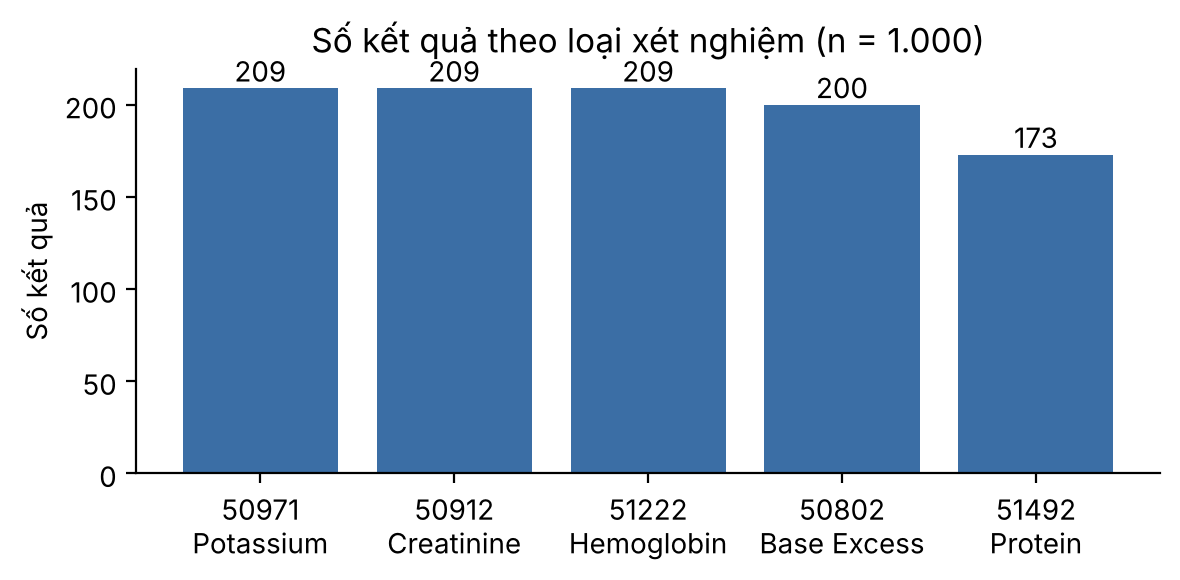

In [7]:
import matplotlib.pyplot as plt

selected["_num"] = pd.to_numeric(selected["valuenum"])
selected["_thieu_can"] = (selected["ref_range_lower"].map(clean).eq("")
                          & selected["ref_range_upper"].map(clean).eq(""))
desc = (selected.groupby("itemid", sort=False)
        .agg(so_ket_qua=("labevent_id", "size"), so_benh_nhan=("subject_id", "nunique"),
             don_vi=("valueuom", "first"), min=("_num", "min"), trung_vi=("_num", "median"),
             max=("_num", "max"), thieu_can=("_thieu_can", "sum"))
        .reindex(list(QUOTAS)).reset_index())
desc.insert(1, "xet_nghiem", desc["itemid"].map(cat["label"]))
display(desc)

per_patient_stats = pd.DataFrame({"min": [per_patient.min()], "trung_vi": [per_patient.median()],
                                  "max": [per_patient.max()], "so_benh_nhan": [len(per_patient)]})
display(per_patient_stats)

fig, ax = plt.subplots(figsize=(6, 3))
labels = [f"{r.itemid}\n{r.xet_nghiem}" for r in desc.itertuples()]
bars = ax.bar(labels, desc["so_ket_qua"], color="#3b6ea5")
ax.bar_label(bars)
ax.set_ylabel("Số kết quả")
ax.set_title("Số kết quả theo loại xét nghiệm (n = 1.000)")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 8. Đối chiếu với danh sách E1 (không bắt buộc)

Nếu có file `data/external/e1_1000_ids.csv` (một cột `labevent_id`) thì so sánh với danh sách vừa chọn.
Không có file này thì chưa đối chiếu được. Việc thiếu file không phải là lỗi.

In [8]:
E1_PATH = ROOT / "data" / "external" / "e1_1000_ids.csv"
e1_comparison = None
if E1_PATH.is_file():
    e1 = pd.read_csv(E1_PATH, dtype="string", keep_default_na=False)
    e1_ids, new_ids = set(e1["labevent_id"].str.strip()), set(selected["labevent_id"])
    e1_comparison = {"chung": len(e1_ids & new_ids), "chi_co_o_e1": len(e1_ids - new_ids),
                     "chi_co_o_danh_sach_moi": len(new_ids - e1_ids)}
    display(pd.DataFrame([e1_comparison]))
else:
    print("Chưa đối chiếu với danh sách E1. Cần lấy danh sách ID thực tế đã nạp vào LIS "
          "ở đợt chạy E1 trong repo lis-fhir-emr.")

Chưa đối chiếu với danh sách E1. Cần lấy danh sách ID thực tế đã nạp vào LIS ở đợt chạy E1 trong repo lis-fhir-emr.


## 9. Xuất kết quả vào `reports/`

Xuất 3 file: danh sách 1.000 kết quả, bảng kiểm tra, và bản tóm tắt.
Tóm tắt ghi SHA-256 danh sách ID và SHA-256 của chính file danh sách, cùng một đoạn văn có thể dùng cho mục "Dữ liệu" của chương 3.

In [9]:
MANIFEST_COLS = ["labevent_id", "subject_id", "itemid", "label", "fluid", "category", "charttime", "value",
                 "valuenum", "valueuom", "ref_range_lower", "ref_range_upper", "selection_reason",
                 "round", "csv_record"]
manifest = selected[MANIFEST_COLS].copy()
manifest["_id"] = manifest["labevent_id"].astype(int)
manifest = manifest.sort_values(["itemid", "_id"]).drop(columns="_id")
manifest_path = REPORTS / "sample_selection_manifest_1000.csv"
checks_path = REPORTS / "sample_selection_1000_checks.csv"
summary_path = REPORTS / "sample_selection_1000_summary.md"
manifest.to_csv(manifest_path, index=False, encoding="utf-8-sig")
checks_df.to_csv(checks_path, index=False, encoding="utf-8-sig")
manifest_sha = file_sha256(manifest_path)

dist_lines = "\n".join(
    f"| {r.itemid} | {r.xet_nghiem} | {r.so_ket_qua} | {r.so_benh_nhan} | {r.don_vi} |"
    for r in desc.itertuples())
n_core_in = len(core_ids & set(selected["labevent_id"]))
n_both = int((~low_missing & ~high_missing).sum())
n_none = int((low_missing & high_missing).sum())
n_zero, n_neg = int(sum(v == 0 for v in values)), int(sum(v < 0 for v in values))
n_rr = int((selected["selection_reason"] == "round_robin").sum())
e1_line = (f"Đối chiếu E1: {e1_comparison['chung']} ID chung, {e1_comparison['chi_co_o_e1']} ID chỉ có ở E1, "
           f"{e1_comparison['chi_co_o_danh_sach_moi']} ID chỉ có ở danh sách mới."
           if e1_comparison else "Đối chiếu E1: chưa làm (chưa có `data/external/e1_1000_ids.csv`).")

paragraph = (
    f"Thực nghiệm E1 dùng {len(selected)} kết quả xét nghiệm của {selected['subject_id'].nunique()}/{len(patients)} "
    f"bệnh nhân trong MIMIC-IV Clinical Database Demo 2.2. Trước tiên, {n_pass}/{len(labevents)} dòng đạt sàng lọc cơ bản "
    f"(giá trị là số, có đơn vị, thời gian hợp lệ, cận tham chiếu hợp lệ, không có ghi chú). "
    f"Từ đó chọn 5 loại xét nghiệm với hạn mức cố định 209, 209, 209, 200 và 173 kết quả. "
    f"Trong mỗi loại, {n_core_in}/{len(core_ids)} kết quả lõi (đã chốt ở chương 2) được lấy trước, "
    f"phần còn lại ({n_rr} kết quả) xoay vòng theo bệnh nhân, theo thời gian từ sớm đến muộn. "
    f"Tập này gồm {n_both} kết quả đủ hai cận tham chiếu, {n_none} kết quả thiếu cả hai cận, "
    f"{n_zero} giá trị bằng 0 và {n_neg} giá trị âm. "
    f"Đây là chọn mẫu có chủ đích theo quy tắc cố định, không phải mẫu ngẫu nhiên của toàn bộ MIMIC-IV."
)

summary_md = f"""# Chọn mẫu 1.000 kết quả cho E1 — tóm tắt

Nguồn: MIMIC-IV Clinical Database Demo 2.2 (hash 3 file nén khớp notebook 04). Quy tắc: `docs/quy_tac_chon_mau_1000.md`.

## Kết quả kiểm tra

- Phép kiểm đạt: **{n_ok}/{len(checks_df)}**.
- Dòng đạt sàng lọc cơ bản: {n_pass}/{len(labevents)}.
- Kết quả lõi có trong tập: {n_core_in}/{len(core_ids)}.
- Số kết quả mỗi bệnh nhân: ít nhất {per_patient.min()}, trung vị {num(per_patient.median())}, nhiều nhất {per_patient.max()} ({len(per_patient)} bệnh nhân).
- {e1_line}

## Phân bố theo loại xét nghiệm

| itemid | Xét nghiệm | Số kết quả | Số bệnh nhân | Đơn vị |
|---|---|---|---|---|
{dist_lines}

## Mã băm (SHA-256)

- Danh sách `labevent_id` (xếp tăng dần theo số, mỗi ID một dòng): `{ids_sha}`
- File `sample_selection_manifest_1000.csv`: `{manifest_sha}`

## Đoạn văn cho mục "Dữ liệu" (chương 3)

{paragraph}
"""
summary_path.write_text(summary_md, encoding="utf-8")
for p in (manifest_path, checks_path, summary_path):
    print("Đã lưu:", p.relative_to(ROOT))
print("SHA-256 danh sách ID:", ids_sha)
print("SHA-256 file manifest:", manifest_sha)

Đã lưu: reports/sample_selection_manifest_1000.csv
Đã lưu: reports/sample_selection_1000_checks.csv
Đã lưu: reports/sample_selection_1000_summary.md
SHA-256 danh sách ID: 812e5a8917a269e3b9bbb686ebbef0866014c060eb545a32aa05bc0709e6ae6e
SHA-256 file manifest: e5f01b30a89e68662944d48c9e369fd122309d912fd5763cc14184e3fb6520b7


## 10. Kết luận

- Đã chứng minh: quy tắc trong tài liệu, chạy trên CSV MIMIC-IV Demo 2.2 thật, cho ra đúng 1.000 kết quả khớp mọi giá trị kỳ vọng, gồm 40/40 kết quả lõi, và chạy lại luôn ra cùng danh sách.
- Đã chứng minh: mọi dòng được chọn đạt sàng lọc cơ bản, thuộc 5 loại xét nghiệm, và mỗi loại chỉ có một đơn vị đo.
- Chưa chứng minh: đây là chọn mẫu có chủ đích. Nó không phải mẫu ngẫu nhiên và không nói được gì về toàn bộ MIMIC-IV hay về bệnh viện thật.
- Chưa chứng minh: danh sách này trùng với danh sách đã nạp vào LIS ở đợt chạy E1. Cần đối chiếu (mục 8) trước khi đưa số liệu E1 vào chương 3.